# Entraînement et validation visuelle YOLO avec copy-paste

Ce notebook permet de :

1. définir tous les paramètres dans une seule cellule ;
2. contrôler les images et les boîtes produites par le générateur ;
3. lancer facultativement un entraînement YOLO ;
4. charger `best.pt` et afficher ses prédictions sur de vraies images.

Exécuter les cellules dans l'ordre. Pour seulement tester un modèle déjà entraîné, laisser `TRAIN_MODEL = False`.

In [38]:
from pathlib import Path
import gc
import importlib
import json
import secrets
import sys

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

# Retrouve la racine du projet, même si le notebook est lancé depuis son dossier.
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "data_augmentation").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data_augmentation").is_dir():
    raise FileNotFoundError("Racine du projet AquaIA introuvable.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data_augmentation.detection_augmentation import copy_paste_dataset
importlib.reload(copy_paste_dataset)
from data_augmentation.detection_augmentation.copy_paste_dataset import (
    CopyPasteDataset,
    evaluate_yolo_test,
    train_yolo_copy_paste,
)

print(f"Projet : {PROJECT_ROOT}")

Projet : /home/benjamin.yang/Documents/AKKODIS/AquaIA


## Paramètres

C'est normalement la seule cellule à modifier.

In [73]:
# Recharge le générateur si son fichier Python a été modifié depuis le démarrage du kernel.
copy_paste_dataset = importlib.reload(copy_paste_dataset)
CopyPasteDataset = copy_paste_dataset.CopyPasteDataset
evaluate_yolo_test = copy_paste_dataset.evaluate_yolo_test
train_yolo_copy_paste = copy_paste_dataset.train_yolo_copy_paste

# Dossiers utilisés par le générateur
CUTOUT_DIR = PROJECT_ROOT / "datasets/LPL_dataset_cutouts_single"
BACKGROUND_DIR = PROJECT_ROOT / "datasets/Images_fond_blanc_&_bruits"
# True : les 8 fonds (propres + bruités) ; False : les 4 fonds sans bruit.
USE_NOISY_BACKGROUNDS = True
BACKGROUND_KIND = "all" if USE_NOISY_BACKGROUNDS else "clean"

# Génération des images
IMAGE_SIZE = 1024
TRAIN_IMAGES_PER_EPOCH = 200
VAL_IMAGES = 100
TEST_IMAGES = 200
MIN_MACROINVERTEBRATES = 4
MAX_MACROINVERTEBRATES = 15
PADDING = 0.08
MAX_ROTATION = 180
CUTOUT_SCALE_RANGE = (0.8, 1.2)
ALLOW_OVERLAP = False
IOU_MAX = 1.0
MULTI_CLASS = False
SEED = 42
CLASS_MODE = "multi" if MULTI_CLASS else "single"
TEST_MANIFEST = PROJECT_ROOT / (
    f"datasets/copy_paste_test_manifest_{CUTOUT_DIR.name}_{CLASS_MODE}_"
    f"{BACKGROUND_KIND}_{MIN_MACROINVERTEBRATES}_{MAX_MACROINVERTEBRATES}.json"
)

# Entraînement : passer à True pour entraîner, False pour seulement tester best.pt
TRAIN_MODEL = True
MODEL_ID = "yolo26n.pt"
EPOCHS = 10
BATCH_SIZE = 4
WORKERS = 2
TRAIN_OUTPUT = PROJECT_ROOT / "results/detection/copy_paste_yolo"

# Paramètres YOLO supplémentaires
# DEVICE peut valoir "auto", "cpu" ou 0 pour imposer le premier GPU.
DEVICE = "auto"
ALLOW_CPU_FALLBACK = False
TRAINING_PARAMETERS = {
    "device": 0,
    "optimizer": "AdamW",
    "lr0": 0.0005,
    "amp": True,
    "plots": True,
    "patience": 15,
    "hsv_h": 0.015,
    "hsv_s": 0.3,
    "hsv_v": 0.3,
    "fliplr": 0.5,
    "scale": 0.2,
    "translate": 0.1,
}

# Validation visuelle après entraînement
WEIGHTS_PATH = TRAIN_OUTPUT / "train/weights/best.pt"
VALIDATION_SOURCE = PROJECT_ROOT / "datasets/DATA/LPL_Photos_190826"
# Labels YOLO correspondant aux vraies images. L'évaluation est ignorée s'ils manquent.
VALIDATION_LABELS = CUTOUT_DIR / "labels"
PREDICTION_OUTPUT = PROJECT_ROOT / "results/detection/copy_paste_predictions"
REAL_METRICS_OUTPUT = PROJECT_ROOT / "results/detection/real_test_metrics"
RUN_REAL_METRICS = True
CONFIDENCE = 0.5
MAX_PREDICTIONS_TO_DISPLAY = 10
RUN_TEST_METRICS = True
# Seuil utilisé uniquement pour compter TP, FP et FN (la mAP garde son calcul standard).
TEST_CONFIDENCE = 0.25
TEST_METRICS_OUTPUT = PROJECT_ROOT / "results/detection/copy_paste_test_metrics"
RANDOM_GENERATED_IMAGES = 3

# Nombre d'images synthétiques à afficher avant l'entraînement
PREVIEW_COUNT = 4

print(f"Modèle : {MODEL_ID}")
print(f"Taille d'entrée : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Lancer l'entraînement : {TRAIN_MODEL}")
print(f"CUDA annoncé par PyTorch : {torch.cuda.is_available()}")

Modèle : yolo26n.pt
Taille d'entrée : 1024 x 1024
Lancer l'entraînement : True
CUDA annoncé par PyTorch : True


## 1. Vérifier les images synthétiques et leurs annotations

Cette cellule affiche des images de validation déterministes avec les vraies boîtes envoyées au modèle.

Préparation de 8 fond(s) avec et sans bruit en (1024, 1024)...


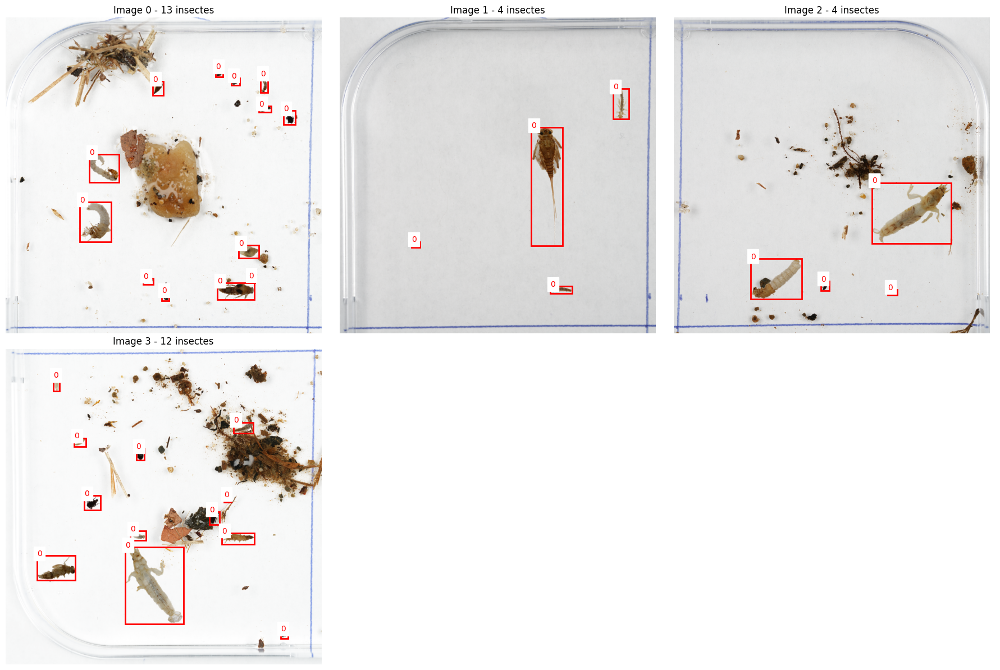

In [66]:
preview_dataset = CopyPasteDataset(
    cutout_dir=CUTOUT_DIR,
    background_dir=BACKGROUND_DIR,
    length=PREVIEW_COUNT,
    image_size=IMAGE_SIZE,
    split="val",
    seed=SEED,
    min_macroinvertebrates=MIN_MACROINVERTEBRATES,
    max_macroinvertebrates=MAX_MACROINVERTEBRATES,
    padding=PADDING,
    max_rotation=MAX_ROTATION,
    cutout_scale_range=CUTOUT_SCALE_RANGE,
    allow_overlap=ALLOW_OVERLAP,
    iou_max=IOU_MAX,
    multi_class=MULTI_CLASS,
    use_noisy_backgrounds=USE_NOISY_BACKGROUNDS,
)

columns = 3
rows = (PREVIEW_COUNT + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(18, 6 * rows))
axes = axes.ravel() if hasattr(axes, "ravel") else [axes]

for index, axis in enumerate(axes):
    axis.axis("off")
    if index >= PREVIEW_COUNT:
        continue

    sample = preview_dataset[index]
    image = sample["image"].permute(1, 2, 0).numpy()
    axis.imshow(image)
    axis.set_title(f"Image {index} - {len(sample['target']['boxes'])} insectes")

    for class_id, (center_x, center_y, width, height) in zip(
        sample["target"]["labels"], sample["target"]["boxes"]
    ):
        left = (center_x - width / 2) * IMAGE_SIZE
        top = (center_y - height / 2) * IMAGE_SIZE
        axis.add_patch(
            Rectangle(
                (left, top),
                width * IMAGE_SIZE,
                height * IMAGE_SIZE,
                fill=False,
                color="red",
                linewidth=2,
            )
        )
        axis.text(left, top, str(int(class_id)), color="red", backgroundcolor="white")

plt.tight_layout()
plt.show()

## 2. Entraîner YOLO

La cellule ne fait rien si `TRAIN_MODEL = False`. Après l'entraînement, `WEIGHTS_PATH` est automatiquement remplacé par le chemin réel de `best.pt`.

In [67]:
trained_model = None

if TRAIN_MODEL:
    # is_available() ne suffit pas toujours : on teste une vraie allocation.
    gc.collect()
    cuda_error = None
    cuda_ready = False
    if torch.cuda.is_available():
        try:
            torch.cuda.empty_cache()
            cuda_test = torch.zeros(1, device="cuda:0")
            del cuda_test
            cuda_ready = True
        except Exception as error:
            cuda_error = error

    requested_device = TRAINING_PARAMETERS.get("device", "auto")
    wants_cuda = requested_device != "cpu"
    if wants_cuda and not cuda_ready and not ALLOW_CPU_FALLBACK:
        raise RuntimeError(
            "CUDA n'est pas utilisable dans ce kernel. Redémarrer le kernel, "
            "fermer les notebooks utilisant SAM, puis vérifier `nvidia-smi` dans un terminal. "
            f"Erreur CUDA : {cuda_error or 'aucun GPU détecté'}"
        )

    effective_training_parameters = dict(TRAINING_PARAMETERS)
    if requested_device == "auto":
        effective_training_parameters["device"] = 0 if cuda_ready else "cpu"
    print(f"Appareil utilisé : {effective_training_parameters['device']}")

    trained_model, metrics = train_yolo_copy_paste(
        model_id=MODEL_ID,
        cutout_dir=CUTOUT_DIR,
        background_dir=BACKGROUND_DIR,
        image_size=IMAGE_SIZE,
        train_length=TRAIN_IMAGES_PER_EPOCH,
        val_length=VAL_IMAGES,
        test_length=TEST_IMAGES,
        test_manifest_path=TEST_MANIFEST,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        workers=WORKERS,
        seed=SEED,
        project=TRAIN_OUTPUT,
        min_macroinvertebrates=MIN_MACROINVERTEBRATES,
        max_macroinvertebrates=MAX_MACROINVERTEBRATES,
        padding=PADDING,
        max_rotation=MAX_ROTATION,
        cutout_scale_range=CUTOUT_SCALE_RANGE,
        allow_overlap=ALLOW_OVERLAP,
        iou_max=IOU_MAX,
        multi_class=MULTI_CLASS,
        use_noisy_backgrounds=USE_NOISY_BACKGROUNDS,
        training_parameters=effective_training_parameters,
    )
    WEIGHTS_PATH = Path(trained_model.trainer.best)
    print(f"Meilleurs poids : {WEIGHTS_PATH}")
else:
    print(f"Entraînement ignoré. Poids utilisés pour la prédiction : {WEIGHTS_PATH}")

Appareil utilisé : 0
New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.171 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX A3000 Laptop GPU, 5806MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=copy_paste, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.3, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

## 3. Mesurer les performances sur le dataset de test

En détection, une simple accuracy est ambiguë : une prédiction doit avoir la bonne classe et une boîte suffisamment proche. On utilise donc la précision, le rappel, `mAP@50` et `mAP@50-95`.

Le split test est reconstruit depuis son manifest JSON et reste identique entre les modèles.

Ultralytics 8.4.171 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX A3000 Laptop GPU, 5806MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
Préparation de 8 fond(s) avec et sans bruit en (1024, 1024)...
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 1.1it/s 45.2s0.5ss
                   all        200       1859      0.869      0.819      0.878      0.653
Speed: 0.7ms preprocess, 6.9ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /home/benjamin.yang/Documents/AKKODIS/AquaIA/results/detection/copy_paste_test_metrics/test_metrics

Résultats sur le test synthétique :
Précision    :  86.88 %
Rappel       :  81.93 %
mAP@50       :  87.84 %
mAP@50-95    :  65.26 %

Comptage à confidence >= 0.25 et IoU >= 0.50 :
Vrais positifs : 1554
Faux positifs : 278
Faux négatifs : 305
Précision      : 84.83 %
Rappel         : 83.59 %
F1-score       : 84.20 %
Les vrais nég

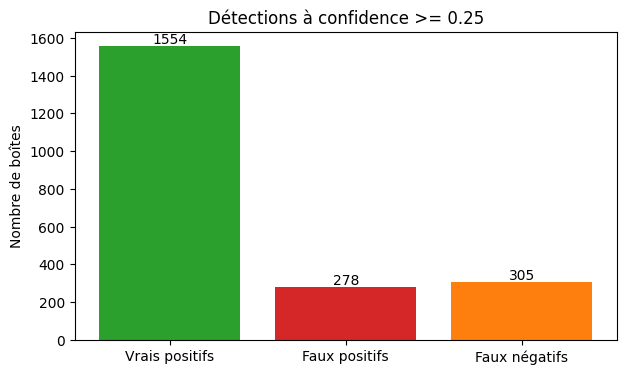

In [68]:
test_metrics = None

if RUN_TEST_METRICS:
    if not WEIGHTS_PATH.is_file() and trained_model is None:
        raise FileNotFoundError(
            f"Poids introuvables : {WEIGHTS_PATH}\n"
            "Lancer l'entraînement ou corriger WEIGHTS_PATH."
        )

    test_device = TRAINING_PARAMETERS.get("device", "auto")
    if test_device == "auto":
        test_device = 0 if torch.cuda.is_available() else "cpu"
    if test_device == "cpu" and not ALLOW_CPU_FALLBACK:
        raise RuntimeError(
            "CUDA est indisponible. Corriger CUDA ou mettre ALLOW_CPU_FALLBACK = True "
            "pour évaluer volontairement sur CPU."
        )

    test_metrics = evaluate_yolo_test(
        model_or_weights=trained_model or str(WEIGHTS_PATH),
        cutout_dir=CUTOUT_DIR,
        background_dir=BACKGROUND_DIR,
        output_dir=TEST_METRICS_OUTPUT,
        test_manifest_path=TEST_MANIFEST,
        image_size=IMAGE_SIZE,
        test_length=TEST_IMAGES,
        batch_size=BATCH_SIZE,
        workers=WORKERS,
        seed=SEED,
        device=test_device,
        min_macroinvertebrates=MIN_MACROINVERTEBRATES,
        max_macroinvertebrates=MAX_MACROINVERTEBRATES,
        padding=PADDING,
        max_rotation=MAX_ROTATION,
        cutout_scale_range=CUTOUT_SCALE_RANGE,
        allow_overlap=ALLOW_OVERLAP,
        iou_max=IOU_MAX,
        multi_class=MULTI_CLASS,
        use_noisy_backgrounds=USE_NOISY_BACKGROUNDS,
    )

    readable_names = {
        "metrics/precision(B)": "Précision",
        "metrics/recall(B)": "Rappel",
        "metrics/mAP50(B)": "mAP@50",
        "metrics/mAP50-95(B)": "mAP@50-95",
    }
    print("\nRésultats sur le test synthétique :")
    for key, label in readable_names.items():
        if key in test_metrics.results_dict:
            print(f"{label:12s} : {100 * test_metrics.results_dict[key]:6.2f} %")


    # Comptage à un vrai seuil d'utilisation, au lieu du seuil très bas de la mAP.
    raw_stats = test_metrics.raw_stats
    selected = raw_stats["conf"] >= TEST_CONFIDENCE
    true_positives = raw_stats["tp"][selected, 0].sum()
    false_positives = selected.sum() - true_positives
    false_negatives = len(raw_stats["target_cls"]) - true_positives

    precision = true_positives / max(true_positives + false_positives, 1)
    recall = true_positives / max(true_positives + false_negatives, 1)
    f1_score = 2 * precision * recall / max(precision + recall, 1e-12)

    print(f"\nComptage à confidence >= {TEST_CONFIDENCE:.2f} et IoU >= 0.50 :")
    print(f"Vrais positifs : {true_positives:.0f}")
    print(f"Faux positifs : {false_positives:.0f}")
    print(f"Faux négatifs : {false_negatives:.0f}")
    print(f"Précision      : {100 * precision:.2f} %")
    print(f"Rappel         : {100 * recall:.2f} %")
    print(f"F1-score       : {100 * f1_score:.2f} %")
    print("Les vrais négatifs ne sont pas définis en détection d'objets.")

    fig, axis = plt.subplots(figsize=(7, 4))
    values = [true_positives, false_positives, false_negatives]
    bars = axis.bar(["Vrais positifs", "Faux positifs", "Faux négatifs"], values,
                    color=["#2ca02c", "#d62728", "#ff7f0e"])
    axis.bar_label(bars, fmt="%.0f")
    axis.set_title(f"Détections à confidence >= {TEST_CONFIDENCE:.2f}")
    axis.set_ylabel("Nombre de boîtes")
    plt.show()
else:
    print("Évaluation quantitative ignorée : RUN_TEST_METRICS = False")

## 4. Comparer vérité terrain et prédictions sur de nouvelles images générées

Cette cellule utilise une nouvelle seed à chaque exécution. La colonne de gauche montre les vraies boîtes et celle de droite les prédictions du modèle. Relancer uniquement cette cellule produit de nouvelles compositions.

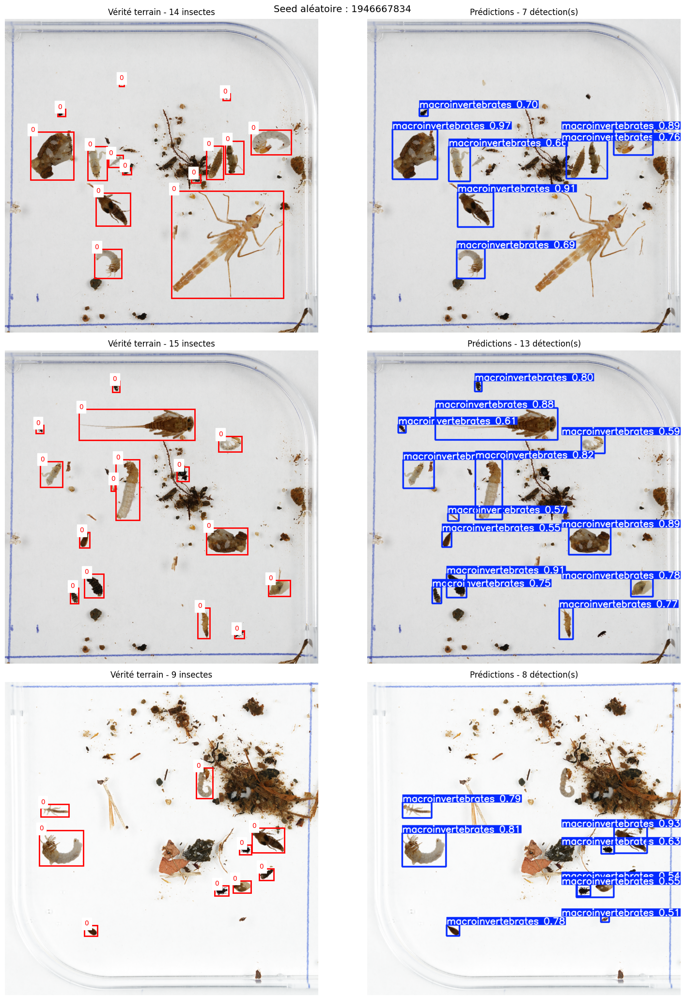

In [69]:
active_trained_model = globals().get("trained_model")
if not WEIGHTS_PATH.is_file() and active_trained_model is None:
    raise FileNotFoundError(
        f"Poids introuvables : {WEIGHTS_PATH}\n"
        "Lancer l'entraînement ou corriger WEIGHTS_PATH."
    )
if RANDOM_GENERATED_IMAGES < 1:
    raise ValueError("RANDOM_GENERATED_IMAGES doit être supérieur à zéro.")

# Nouvelle seed à chaque exécution de la cellule.
random_seed = secrets.randbits(31)
shared_cache = None
if "preview_dataset" in globals() and preview_dataset.use_noisy_backgrounds == USE_NOISY_BACKGROUNDS:
    shared_cache = preview_dataset.background_cache

random_dataset = CopyPasteDataset(
    cutout_dir=CUTOUT_DIR,
    background_dir=BACKGROUND_DIR,
    length=RANDOM_GENERATED_IMAGES,
    image_size=IMAGE_SIZE,
    split="val",
    seed=random_seed,
    min_macroinvertebrates=MIN_MACROINVERTEBRATES,
    max_macroinvertebrates=MAX_MACROINVERTEBRATES,
    padding=PADDING,
    max_rotation=MAX_ROTATION,
    cutout_scale_range=CUTOUT_SCALE_RANGE,
    allow_overlap=ALLOW_OVERLAP,
    iou_max=IOU_MAX,
    multi_class=MULTI_CLASS,
    use_noisy_backgrounds=USE_NOISY_BACKGROUNDS,
    background_cache=shared_cache,
)
random_samples = [random_dataset[index] for index in range(RANDOM_GENERATED_IMAGES)]
random_images = [
    Image.fromarray((sample["image"].permute(1, 2, 0).numpy() * 255).astype("uint8"))
    for sample in random_samples
]

random_model = active_trained_model or YOLO(str(WEIGHTS_PATH))
random_results = random_model.predict(
    source=random_images,
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE,
    verbose=False,
)

fig, axes = plt.subplots(RANDOM_GENERATED_IMAGES, 2, figsize=(16, 7 * RANDOM_GENERATED_IMAGES), squeeze=False)
for index, (sample, image, result) in enumerate(zip(random_samples, random_images, random_results)):
    axes[index, 0].imshow(image)
    axes[index, 0].set_title(f"Vérité terrain - {len(sample['target']['boxes'])} insectes")
    axes[index, 0].axis("off")
    for class_id, box in zip(sample["target"]["labels"], sample["target"]["boxes"]):
        center_x, center_y, width, height = box.tolist()
        left = (center_x - width / 2) * IMAGE_SIZE
        top = (center_y - height / 2) * IMAGE_SIZE
        axes[index, 0].add_patch(
            Rectangle(
                (left, top), width * IMAGE_SIZE, height * IMAGE_SIZE,
                fill=False, color="red", linewidth=2,
            )
        )
        axes[index, 0].text(left, top, str(int(class_id)), color="red", backgroundcolor="white")

    axes[index, 1].imshow(result.plot()[..., ::-1])
    axes[index, 1].set_title(f"Prédictions - {len(result.boxes)} détection(s)")
    axes[index, 1].axis("off")

plt.suptitle(f"Seed aléatoire : {random_seed}", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Prédire et afficher de vraies images

`VALIDATION_SOURCE` peut désigner une image ou un dossier. Seules les premières images sont affichées, mais leurs prédictions sont également enregistrées sur le disque.

Si les labels YOLO correspondants sont présents dans `VALIDATION_LABELS`, le notebook calcule aussi la précision, le rappel, `mAP@50` et `mAP@50-95` sur toutes les images réelles. Sans labels, cette partie est simplement ignorée.

0: 768x1024 5 macroinvertebratess, 5.4ms
1: 768x1024 7 macroinvertebratess, 5.4ms
2: 768x1024 5 macroinvertebratess, 5.4ms
3: 768x1024 4 macroinvertebratess, 5.4ms
4: 768x1024 6 macroinvertebratess, 5.4ms
5: 768x1024 6 macroinvertebratess, 5.4ms
6: 768x1024 6 macroinvertebratess, 5.4ms
7: 768x1024 8 macroinvertebratess, 5.4ms
8: 768x1024 8 macroinvertebratess, 5.4ms
Speed: 8.3ms preprocess, 5.4ms inference, 1.2ms postprocess per image at shape (1, 3, 768, 1024)
Results saved to /home/benjamin.yang/Documents/AKKODIS/AquaIA/results/detection/copy_paste_predictions/predictions


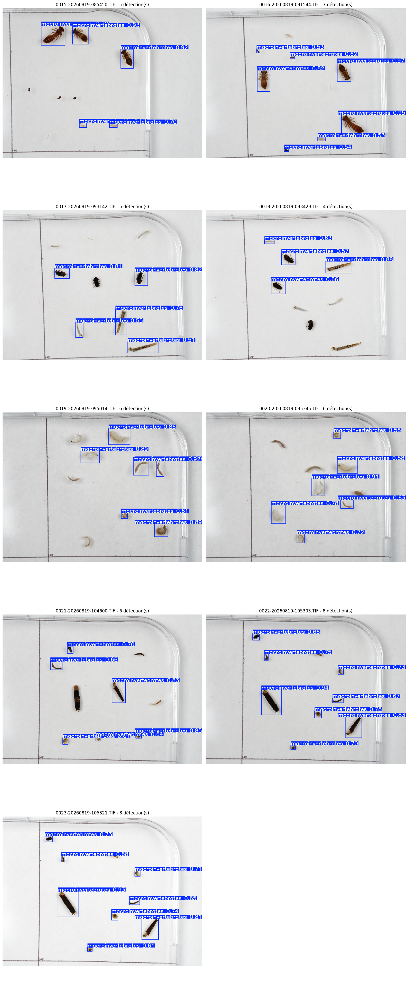

Prédictions enregistrées dans : /home/benjamin.yang/Documents/AKKODIS/AquaIA/results/detection/copy_paste_predictions/predictions


In [72]:
if not WEIGHTS_PATH.is_file() and trained_model is None:
    raise FileNotFoundError(
        f"Poids introuvables : {WEIGHTS_PATH}\n"
        "Lancer l'entraînement ou corriger WEIGHTS_PATH dans la cellule des paramètres."
    )

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
if VALIDATION_SOURCE.is_dir():
    all_image_paths = [
        path for path in sorted(VALIDATION_SOURCE.rglob("*"))
        if path.suffix.lower() in extensions
    ]
else:
    all_image_paths = [VALIDATION_SOURCE]

image_paths = all_image_paths[:MAX_PREDICTIONS_TO_DISPLAY]

if not image_paths:
    raise FileNotFoundError(f"Aucune image trouvée dans {VALIDATION_SOURCE}")

prediction_model = trained_model or YOLO(str(WEIGHTS_PATH))
results = prediction_model.predict(
    source=[str(path) for path in image_paths],
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE,
    save=True,
    project=str(PREDICTION_OUTPUT),
    name="predictions",
    exist_ok=True,
)

columns = 2
rows = (len(results) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(16, 8 * rows))
axes = axes.ravel() if hasattr(axes, "ravel") else [axes]

for axis in axes:
    axis.axis("off")
for axis, result in zip(axes, results):
    axis.imshow(result.plot()[..., ::-1])
    axis.set_title(f"{Path(result.path).name} - {len(result.boxes)} détection(s)")

plt.tight_layout()
plt.show()
print(f"Prédictions enregistrées dans : {PREDICTION_OUTPUT / 'predictions'}")

# La mAP nécessite une vérité terrain : une image sans fichier .txt ne peut pas être évaluée.
if RUN_REAL_METRICS:
    missing_labels = [
        path.name for path in all_image_paths
        if not (VALIDATION_LABELS / f"{path.stem}.txt").is_file()
    ]

    if missing_labels:
        print(
            f"\nMétriques réelles ignorées : {len(missing_labels)}/{len(all_image_paths)} "
            "image(s) n'ont pas de label YOLO correspondant."
        )
        print(f"Dossier de labels attendu : {VALIDATION_LABELS}")
    else:
        # Ultralytics attend deux dossiers frères images/ et labels/.
        dataset_dir = REAL_METRICS_OUTPUT / "dataset"
        real_images_dir = dataset_dir / "images"
        real_labels_dir = dataset_dir / "labels"
        real_images_dir.mkdir(parents=True, exist_ok=True)
        real_labels_dir.mkdir(parents=True, exist_ok=True)

        # Les liens évitent de recopier les lourdes images TIFF.
        for folder in (real_images_dir, real_labels_dir):
            for old_link in folder.iterdir():
                if old_link.is_symlink():
                    old_link.unlink()

        for image_path in all_image_paths:
            (real_images_dir / image_path.name).symlink_to(image_path.resolve())
            label_path = VALIDATION_LABELS / f"{image_path.stem}.txt"
            (real_labels_dir / label_path.name).symlink_to(label_path.resolve())

        data_file = REAL_METRICS_OUTPUT / "real_test_dataset.yaml"
        data_file.parent.mkdir(parents=True, exist_ok=True)
        data_file.write_text(
            json.dumps({
                "path": str(dataset_dir.resolve()),
                "test": "images",
                "names": {0: "macroinvertebrates"},
            }, indent=2, ensure_ascii=False) + "\n",
            encoding="utf-8",
        )

        real_device = TRAINING_PARAMETERS.get("device", "auto")
        if real_device == "auto":
            real_device = 0 if torch.cuda.is_available() else "cpu"

        real_metrics = prediction_model.val(
            data=str(data_file),
            split="test",
            imgsz=IMAGE_SIZE,
            batch=BATCH_SIZE,
            workers=WORKERS,
            device=real_device,
            plots=True,
            project=str(REAL_METRICS_OUTPUT),
            name="metrics",
            exist_ok=True,
        )

        metric_keys = {
            "metrics/precision(B)": "precision",
            "metrics/recall(B)": "recall",
            "metrics/mAP50(B)": "map50",
            "metrics/mAP50-95(B)": "map50_95",
        }
        saved_metrics = {
            name: float(real_metrics.results_dict[key])
            for key, name in metric_keys.items()
            if key in real_metrics.results_dict
        }
        saved_metrics["images"] = len(all_image_paths)

        metrics_file = REAL_METRICS_OUTPUT / "real_test_metrics.json"
        metrics_file.write_text(
            json.dumps(saved_metrics, indent=2, ensure_ascii=False) + "\n",
            encoding="utf-8",
        )

        print("\nRésultats sur les vraies images :")
        print(f"Précision : {100 * saved_metrics['precision']:.2f} %")
        print(f"Rappel    : {100 * saved_metrics['recall']:.2f} %")
        print(f"mAP@50    : {100 * saved_metrics['map50']:.2f} %")
        print(f"mAP@50-95 : {100 * saved_metrics['map50_95']:.2f} %")
        print(f"Métriques enregistrées dans : {metrics_file}")
else:
    print("Évaluation quantitative réelle ignorée : RUN_REAL_METRICS = False")

## Lecture rapide des résultats

- Une boîte absente peut venir d'un seuil `CONFIDENCE` trop élevé : essayer `0.15`.
- Beaucoup de fausses détections peuvent nécessiter un seuil plus élevé, par exemple `0.40`.
- Pour une comparaison correcte, conserver le même `IMAGE_SIZE` qu'à l'entraînement.
- Les images `val_batch*_labels.jpg` et `val_batch*_pred.jpg` du dossier d'entraînement permettent aussi de comparer annotations et prédictions.
- Toujours compléter le test synthétique avec de vraies images jamais utilisées pendant l'entraînement.